## PROFANITY FILTERS

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

In [ ]:
import nltk
nltk.download('all')

from nltk.corpus import wordnet
from nltk.corpus import stopwords

from nltk import word_tokenize
from nltk.stem import WordNetLemmatizer

[nltk_data]    | Downloading package framenet_v17 to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Unzipping corpora/framenet_v17.zip.
[nltk_data]    | Downloading package gazetteers to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/gazetteers.zip.
[nltk_data]    | Downloading package genesis to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/genesis.zip.
[nltk_data]    | Downloading package gutenberg to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/gutenberg.zip.
[nltk_data]    | Downloading package ieer to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/ieer.zip.
[nltk_data]    | Downloading package inaugural to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/inaugural.zip.
[nltk_data]    | Downloading package indian to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/indian.zip.
[nltk_data]    | Downloading package jeita to /root/nltk_data...
[nltk_data]    | Downloading package kimmo to /root/nltk_data...
[nltk_data]   

In [ ]:
!7z x text_profanity_data.zip


7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,2 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (406F0),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan         1 file, 28044866 bytes (27 MiB)

Extracting archive: text_profanity_data.zip
--
Path = text_profanity_data.zip
Type = zip
Physical Size = 28044866

  0%     16% - train.csv                 31% - train.csv                 46% - train.csv                 60% - train.csv                 76% - train.csv                 93% - train.csv                Everything is Ok

Size:       68802655
Compressed: 28044866


In [ ]:
data = pd.read_csv(
    'train.csv',
    usecols=[
        'comment_text',
        'toxic',
        'severe_toxic',
        'obscene',
        'threat',
        'insult',
        'identity_hate'
    ]
)
data.head(3)

,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0


In [ ]:
data.isnull().sum()

comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64

In [ ]:
count_duplicates = data.duplicated().sum()
print(f"Found {count_duplicates} duplicate records")

if count_duplicates > 0:
    print(f"... removing duplicates")

    data.drop_duplicates(inplace=True)
    print(f">>> {data.shape[0]} records remain after removing duplicates.")

Found 0 duplicate records


In [ ]:
import re
import joblib
import string

def preprocess_text(input_text):
    text = str(input_text).lower().strip()
    text = text.translate(str.maketrans('','', string.punctuation))

    cleaned_text = re.sub(r'http\S+', '', text)
    cleaned_text = re.sub(r'[^A-Za-z0-9]+', ' ', cleaned_text)
    cleaned_text = re.sub(r"<[^>]*>", "", cleaned_text)
    cleaned_text = re.sub(r"[^\w\s]", " ", cleaned_text)
    cleaned_text = re.sub(r"\d+", "", cleaned_text)

    cleaned_text = cleaned_text.encode("ascii", "ignore").decode()

    tokens = word_tokenize(cleaned_text)
    filtered_tokens = [
        word for word in tokens if word not in set(stopwords.words('english'))
    ]

    lemmatizer = WordNetLemmatizer()
    lemmatized_tokens = [lemmatizer.lemmatize(word) for word in filtered_tokens]

    return " ".join(lemmatized_tokens).strip()


data['cleaned_comment_text'] = data['comment_text'].apply(preprocess_text)
data.head(3)

,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,cleaned_comment_text
0,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,explanation edits made username hardcore metal...
1,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,daww match background colour im seemingly stuc...
2,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,hey man im really trying edit war guy constant...


In [ ]:
data.to_csv('clean_data.csv', index=False)

In [ ]:
X = data['comment_text']
y = data[['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']]

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=50,
)

In [ ]:
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (127656,)
X_test shape: (31915,)


In [ ]:
vectorizer = TfidfVectorizer(
    stop_words='english'
)

X_train_tfidf = vectorizer.fit_transform(X_train)
joblib.dump(vectorizer, 'tfidf_vectorizer.joblib')

X_test_tfidf = vectorizer.transform(X_test)

In [ ]:
clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, verbose=3)
clf.fit(X_train_tfidf, y_train)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.


building tree 1 of 100building tree 2 of 100

building tree 3 of 100
building tree 4 of 100
building tree 5 of 100
building tree 6 of 100
building tree 7 of 100
building tree 8 of 100
building tree 9 of 100
building tree 10 of 100
building tree 11 of 100
building tree 12 of 100
building tree 13 of 100
building tree 14 of 100
building tree 15 of 100
building tree 16 of 100
building tree 17 of 100
building tree 18 of 100
building tree 19 of 100
building tree 20 of 100
building tree 21 of 100
building tree 22 of 100
building tree 23 of 100
building tree 24 of 100
building tree 25 of 100
building tree 26 of 100
building tree 27 of 100
building tree 28 of 100
building tree 29 of 100
building tree 30 of 100


[Parallel(n_jobs=-1)]: Done  28 tasks      | elapsed:  8.2min


building tree 31 of 100
building tree 32 of 100
building tree 33 of 100
building tree 34 of 100
building tree 35 of 100
building tree 36 of 100
building tree 37 of 100
building tree 38 of 100
building tree 39 of 100
building tree 40 of 100
building tree 41 of 100
building tree 42 of 100
building tree 43 of 100
building tree 44 of 100
building tree 45 of 100
building tree 46 of 100
building tree 47 of 100
building tree 48 of 100
building tree 49 of 100
building tree 50 of 100
building tree 51 of 100
building tree 52 of 100
building tree 53 of 100
building tree 54 of 100
building tree 55 of 100
building tree 56 of 100
building tree 57 of 100
building tree 58 of 100
building tree 59 of 100
building tree 60 of 100
building tree 61 of 100
building tree 62 of 100
building tree 63 of 100
building tree 64 of 100
building tree 65 of 100
building tree 66 of 100
building tree 67 of 100
building tree 68 of 100
building tree 69 of 100
building tree 70 of 100
building tree 71 of 100
building tree 72

[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed: 29.7min finished


RandomForestClassifier(n_jobs=-1, random_state=42, verbose=3)

In [ ]:
y_pred_prob = clf.predict_proba(X_test_tfidf)

prob_df = pd.DataFrame(np.hstack([y_pred_prob[i][:, 1].reshape(-1, 1) for i in range(len(y.columns))]), columns=y.columns)

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  28 tasks      | elapsed:    4.1s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:   10.6s finished


In [ ]:
prob_df.head()

,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0.003619,0.000185,0.002584,0.0,0.001307,0.000748
1,0.030000,0.000000,0.000000,0.0,0.010000,0.000000
2,0.040000,0.000000,0.010000,0.0,0.010000,0.000000
3,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
4,0.000000,0.000000,0.000000,0.0,0.000000,0.000000


In [ ]:
y_pred = (prob_df > 0.5).astype(int)
print(classification_report(y_test, y_pred, target_names=y.columns))

               precision    recall  f1-score   support

        toxic       0.87      0.62      0.72      3114
 severe_toxic       0.53      0.08      0.14       317
      obscene       0.89      0.65      0.75      1680
       threat       0.44      0.04      0.08        94
       insult       0.80      0.50      0.61      1593
identity_hate       0.71      0.09      0.15       277

    micro avg       0.85      0.55      0.67      7075
    macro avg       0.71      0.33      0.41      7075
 weighted avg       0.83      0.55      0.65      7075
  samples avg       0.06      0.05      0.05      7075



In [ ]:
prob_df.head()

,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0.003619,0.000185,0.002584,0.0,0.001307,0.000748
1,0.030000,0.000000,0.000000,0.0,0.010000,0.000000
2,0.040000,0.000000,0.010000,0.0,0.010000,0.000000
3,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
4,0.000000,0.000000,0.000000,0.0,0.000000,0.000000


In [ ]:
def predict_toxicity(new_text):
    new_text_tfidf = vectorizer.transform([new_text])
    new_pred_prob = clf.predict_proba(new_text_tfidf)

    new_prob_list = [new_pred_prob[i][0][1] for i in range(6)]
    return new_prob_list


new_text = "A pair of jew-hating weiner nazi schmucks"
print(f"Predictions for new text: {predict_toxicity(new_text)}")

Predictions for new text: [0.87, 0.01, 0.73, 0.0, 0.81, 0.8]


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  28 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.1s finished


In [ ]:
data[data['identity_hate'] > 0.5].head(3)

,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,cleaned_comment_text
42,You are gay or antisemmitian? \n\nArchangel WH...,1,0,1,0,1,1,gay antisemmitian archangel white tiger meow g...
105,A pair of jew-hating weiner nazi schmucks.,1,0,1,0,1,1,pair jewhating weiner nazi schmuck
176,I think that your a Fagget get a oife and burn...,1,0,1,1,1,1,think fagget get oife burn hell hate sorry can...


In [ ]:
import joblib

model_filename = 'random_forest_model.joblib'
joblib.dump(clf, model_filename)

print(f"Model saved to {model_filename}")

Model saved to random_forest_model.joblib


In [ ]:
loaded_model = joblib.load(model_filename)
print("Model loaded successfully")

Model loaded successfully


In [ ]:
def predict_toxicity(new_text, model):
    new_text_tfidf = vectorizer.transform([new_text])
    new_pred_prob = model.predict_proba(new_text_tfidf)
    new_prob_list = [new_pred_prob[i][0][1] for i in range(len(y.columns))]
    return new_prob_list

new_text = "You people are all the same, lazy and worthless. Go back to where you came from nigga!"
predictions = predict_toxicity(new_text, loaded_model)
print(f"Predictions for new text: {predictions}")

Predictions for new text: [0.6, 0.02, 0.27, 0.01, 0.52, 0.34]


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  28 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.1s finished


In [ ]:
predictions

[0.6, 0.02, 0.27, 0.01, 0.52, 0.34]

## TWITTER DASHBOARD

In [ ]:
import gc
import warnings
import pandas as pd
import numpy as np
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

%matplotlib inline
warnings.filterwarnings('ignore')

In [ ]:
import nltk
nltk.download('all')

from nltk.corpus import wordnet
from nltk.corpus import stopwords

from nltk import word_tokenize
from nltk.stem import WordNetLemmatizer

[nltk_data] Downloading collection 'all'
[nltk_data]    | 
[nltk_data]    | Downloading package abc to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/abc.zip.
[nltk_data]    | Downloading package alpino to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/alpino.zip.
[nltk_data]    | Downloading package averaged_perceptron_tagger to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data]    | Downloading package averaged_perceptron_tagger_eng to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Unzipping
[nltk_data]    |       taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data]    | Downloading package averaged_perceptron_tagger_ru to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Unzipping
[nltk_data]    |       taggers/averaged_perceptron_tagger_ru.zip.
[nltk_data]    | Downloading package averaged_perceptron_tagger_rus to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |  

In [3]:
ak_data = pd.read_csv(
    'Arvind Kejriwal_data.csv',
    parse_dates=['Date'],
    date_parser=lambda x: datetime.strptime(x, '%Y:%m:%d'),
)

nm_data = pd.read_csv(
    'Narendra Modi_data.csv',
    parse_dates=['Date'],
    date_parser=lambda x: datetime.strptime(x, '%Y:%m:%d'),
)

rg_data = pd.read_csv(
    'Rahul Gandhi_data.csv',
    parse_dates=['Date'],
    date_parser=lambda x: datetime.strptime(x, '%Y:%m:%d'),
)

data = pd.concat([ak_data, nm_data, rg_data], axis=0)

del ak_data
del nm_data
del rg_data
gc.collect()

data.head(3)

,Date,User,Tweet,Time
0,2022-10-19,bhoo_sene,@TajinderBagga Aap leaders are speaking agains...,23:47:01
1,2022-10-19,Madhusu88858324,Bjp Aap se sikh rhi h\nNarendra Modi Manish Si...,23:06:35
2,2022-10-19,PremshilaKumarp,@JaikyYadav16 Arvind kejriwal,22:56:42


In [4]:
data.shape

(210000, 4)

In [5]:
data.isnull().sum()

Date     0
User     0
Tweet    0
Time     0
dtype: int64

In [6]:
data.dropna(inplace=True)
data.isnull().sum()

Date     0
User     0
Tweet    0
Time     0
dtype: int64

In [7]:
count_duplicates = data.duplicated().sum()
print(f"Found {count_duplicates} duplicate records")

if count_duplicates > 0:
    data.drop_duplicates(inplace=True)
    print(f">>> {data.shape[0]} records remain after removing duplicates.")

Found 1080 duplicate records
>>> 208920 records remain after removing duplicates.


In [8]:
import re
import joblib
import string

def preprocess_text(input_text):
    text = str(input_text).lower().strip()
    text = text.translate(str.maketrans('','', string.punctuation))

    cleaned_text = re.sub(r"(?:\@|http?\://|https?\://|www)\S+", "", text)
    cleaned_text = re.sub(r'[^A-Za-z0-9]+', ' ', cleaned_text)
    cleaned_text = re.sub(r"<[^>]*>", "", cleaned_text)
    cleaned_text = re.sub(r"[^\w\s]", " ", cleaned_text)
    cleaned_text = re.sub(r"\d+", "", cleaned_text)

    cleaned_text = cleaned_text.encode("ascii", "ignore").decode()

    tokens = word_tokenize(cleaned_text)
    filtered_tokens = [
        word for word in tokens if word not in set(stopwords.words('english'))
    ]

    lemmatizer = WordNetLemmatizer()
    lemmatized_tokens = [lemmatizer.lemmatize(word) for word in filtered_tokens]

    return " ".join(lemmatized_tokens).strip()


data['cleaned_tweet'] = data['Tweet'].apply(preprocess_text)
data.head(3)

,Date,User,Tweet,Time,cleaned_tweet
0,2022-10-19,bhoo_sene,@TajinderBagga Aap leaders are speaking agains...,23:47:01,tajinderbagga aap leader speaking hindu god le...
1,2022-10-19,Madhusu88858324,Bjp Aap se sikh rhi h\nNarendra Modi Manish Si...,23:06:35,bjp aap se sikh rhi h narendra modi manish sis...
2,2022-10-19,PremshilaKumarp,@JaikyYadav16 Arvind kejriwal,22:56:42,jaikyyadav arvind kejriwal


In [9]:
def fetch_rows_based_on_search(df, search_string, num_rows=10):
    filtered_df = df[df['cleaned_tweet'].str.contains(search_string, case=False, na=False)]
    result_df = filtered_df.head(num_rows).reset_index(drop=True)

    return result_df

ans = fetch_rows_based_on_search(data, 'India')

In [10]:
ans['Tweet']

0    Kejriwal terms DDC backbone of Delhi's develop...
1    @OpIndia_in Arvind kejriwal big man giving les...
2    Please don't support of Bharatiya Janata party...
3    @jitu_vaghani @EduMinOfGujarat @EduMinOfIndia ...
4    @IndiaHistorypic 2022: Arvind Kejriwal in Aap ...
5    Arvind Kejriwal is Delhi's CM for the third ti...
6    @AamAadmiParty @narendramodi @BJP4India Arvind...
7    @AamAadmiParty @narendramodi @BJP4India Sisodi...
8    @AlboMP Please don't support of Bharatiya Jana...
9    @AamAadmiParty @narendramodi @BJP4India Itne j...
Name: Tweet, dtype: object

In [11]:
from textblob import TextBlob
from wordcloud import WordCloud

pd.options.display.max_colwidth=1000

In [12]:
def get_polarity(tweet):
    return TextBlob(tweet).sentiment.polarity

def get_subjectivity(tweet):
    return TextBlob(tweet).sentiment.subjectivity

def tweet_segmentation(tweet_polarity):
    if tweet_polarity > 0:
        return 'positive'
    elif tweet_polarity == 0 :
        return 'neutral'
    else:
        return 'negative'


data['tweet_polarity']=data['cleaned_tweet'].apply(get_polarity)
data['tweet_subjectivity']=data['cleaned_tweet'].apply(get_subjectivity)
data['sentiment']=data['tweet_polarity'].apply(tweet_segmentation)

In [19]:
import random

# Define countries and their weights
countries = {
    'India': {'weight': 30, 'lat_range': (8, 37), 'long_range': (68, 97)},
    'USA': {'weight': 20, 'lat_range': (24, 49), 'long_range': (-125, -67)},
    'Pakistan': {'weight': 10, 'lat_range': (24, 37), 'long_range': (60, 77)},
    'Nepal': {'weight': 10, 'lat_range': (26, 31), 'long_range': (80, 89)},
    'Bangladesh': {'weight': 5, 'lat_range': (20, 26), 'long_range': (88, 92)},
    'UK': {'weight': 5, 'lat_range': (50, 60), 'long_range': (-10, 2)},
    'Europe': {'weight': 10, 'lat_range': (35, 71), 'long_range': (-10, 40)},
    'China': {'weight': 5, 'lat_range': (20, 53), 'long_range': (73, 135)},
    'Australia': {'weight': 5, 'lat_range': (-44, -10), 'long_range': (112, 154)},
}

countries_list = [country for country, data in countries.items() for _ in range(data['weight'])]
data['country'] = np.random.choice(countries_list, size=len(data))

def generate_coordinates(row):
    country = row['country']
    lat_range = countries[country]['lat_range']
    long_range = countries[country]['long_range']
    lat = random.uniform(lat_range[0], lat_range[1])
    long = random.uniform(long_range[0], long_range[1])
    return pd.Series([lat, long])

data[['lat', 'long']] = data.apply(generate_coordinates, axis=1)

In [20]:
data.head(2)

,Date,User,Tweet,Time,cleaned_tweet,tweet_polarity,tweet_subjectivity,sentiment,country,lat,long
0,2022-10-19,bhoo_sene,@TajinderBagga Aap leaders are speaking against Hindu gods.\nleaders like gopal italia when they open mouth they spew venom against hindus.still arvind kejriwal wants these kind of leaders.\nHindus are watching they are not fools.,23:47:01,tajinderbagga aap leader speaking hindu god leader like gopal italia open mouth spew venom hindusstill arvind kejriwal want kind leader hindu watching fool,0.3,0.7,positive,India,26.366945,84.419448
1,2022-10-19,Madhusu88858324,Bjp Aap se sikh rhi h\nNarendra Modi Manish Sisodiya se sikh rhe h\nAb Modiji ko Hindu Muslim chhor schools me jana pad rha h\n\nSach me Arvind Kejriwal ne Desh kii Rajniti badal dii https://t.co/PLzJ8Ee65C,23:06:35,bjp aap se sikh rhi h narendra modi manish sisodiya se sikh rhe h ab modiji ko hindu muslim chhor school jana pad rha h sach arvind kejriwal ne desh kii rajniti badal dii httpstcoplzjeec,0.0,0.0,neutral,India,36.287055,84.537867


In [21]:
data.drop(columns=['tweet_polarity', 'tweet_subjectivity', 'country'], inplace=True)
data.head(2)

,Date,User,Tweet,Time,cleaned_tweet,sentiment,lat,long
0,2022-10-19,bhoo_sene,@TajinderBagga Aap leaders are speaking against Hindu gods.\nleaders like gopal italia when they open mouth they spew venom against hindus.still arvind kejriwal wants these kind of leaders.\nHindus are watching they are not fools.,23:47:01,tajinderbagga aap leader speaking hindu god leader like gopal italia open mouth spew venom hindusstill arvind kejriwal want kind leader hindu watching fool,positive,26.366945,84.419448
1,2022-10-19,Madhusu88858324,Bjp Aap se sikh rhi h\nNarendra Modi Manish Sisodiya se sikh rhe h\nAb Modiji ko Hindu Muslim chhor schools me jana pad rha h\n\nSach me Arvind Kejriwal ne Desh kii Rajniti badal dii https://t.co/PLzJ8Ee65C,23:06:35,bjp aap se sikh rhi h narendra modi manish sisodiya se sikh rhe h ab modiji ko hindu muslim chhor school jana pad rha h sach arvind kejriwal ne desh kii rajniti badal dii httpstcoplzjeec,neutral,36.287055,84.537867


In [22]:
data.to_csv("processed_data_for_twitter_reporting.csv")

In [ ]:
data.pivot_table(index=['sentiment'],aggfunc={'sentiment':'count'})

,sentiment
sentiment,
negative,21006
neutral,122799
positive,66194


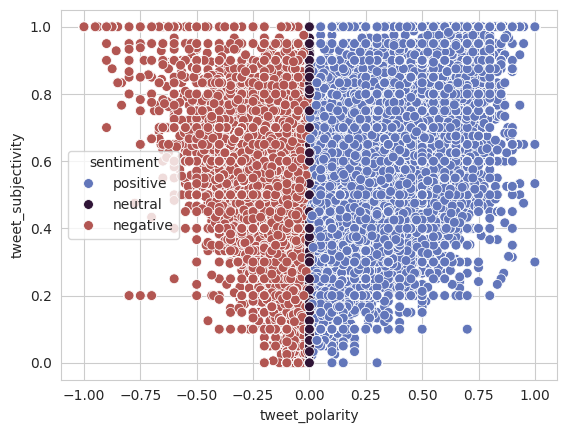

In [ ]:
import seaborn as sns
sns.set_style('whitegrid')
sns.scatterplot(data=data,x='tweet_polarity',y='tweet_subjectivity',s=50,hue='sentiment', palette='twilight')

plt.show()

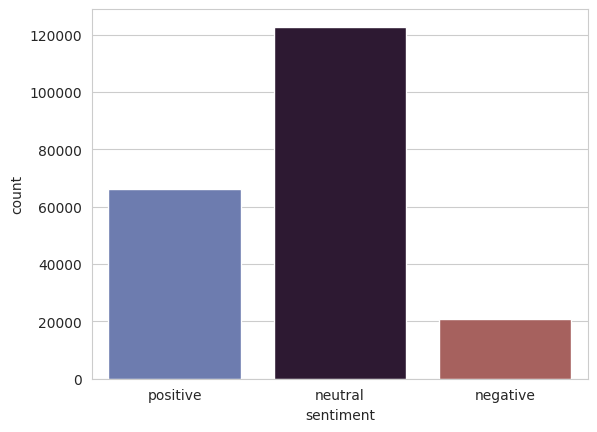

In [ ]:
sns.countplot(data=data,x='sentiment', palette='twilight')
plt.show()

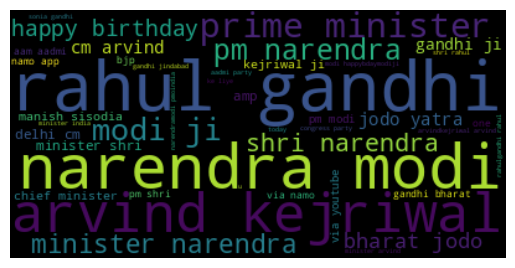

In [ ]:
consolidated=' '.join(word for word in data['cleaned_tweet'])
wordCloud=WordCloud(width=400,height=200,random_state=20,max_font_size=119).generate(consolidated)

plt.imshow(wordCloud,interpolation='bilinear')
plt.axis('off')
plt.show()